# San Jose Metro — Station Placement POC

Loads ACS census data for Santa Clara County using the same feature pipeline as training, scores a candidate grid with your XGBoost model, greedily selects stations, and renders them on a Folium map.

In [11]:
# !pip install requests pandas geopandas shapely folium xgboost --quiet

## 0 — Config

In [12]:
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import folium
from folium.plugins import HeatMap
import xgboost as xgb
import matplotlib.pyplot as plt
import warnings
import sys
sys.path.append('..')
from config import CENSUS_KEY
warnings.filterwarnings('ignore')
MODEL_PATH  = '../models/model.json' # path to your saved XGBoost model
df_model = pd.read_csv('../data/processed/df_model.csv')

# Same variables pulled during training
CENSUS_VARIABLES = [
    'B01003_001E',  # total population
    'B08201_001E',  # total households
    'B08201_002E',  # zero-vehicle households
    'B08201_003E',  # one-vehicle households
    'B08301_001E',  # total commuters
    'B08301_002E',  # drove alone
    'B08301_004E',  # carpooled
    'B08301_010E',  # public transit
    'B23025_001E',  # population 16+ (labor force universe)
    'B23025_004E',  # employed civilians
    'B25003_001E',  # total occupied housing units
    'B25003_003E',  # renter-occupied
    'B19013_001E',  # median household income
]

SJ_COUNTIES      = ['085']   # Santa Clara County only — add more FIPS to expand
GRID_SPACING_KM  = 1.0       # distance between candidate grid points
N_STATIONS       = 20        # station budget
MIN_SPACING_KM   = 2.0       # minimum distance between any two selected stations

# Tight bounding box around Santa Clara County
BOUNDS = (-122.20, 37.10, -121.55, 37.55)  # min_lon, min_lat, max_lon, max_lat

# Must match training feature names exactly
FEATURE_COLS = [
    'Month',
    'Week',
    'population_density',
    'low_car_rate',
    'transit_commuter_rate',
    'driver_rate',
    'carpool_rate',
    'employment_rate',
    'renter_rate',
    'median_income',
    'avg_trip_distance_km',
    'num_unique_destinations',
    'is_weekend_ratio',
    'is_post_covid',
]
CENSUS_FEATURE_COLS = [
    'population_density',
    'low_car_rate',
    'transit_commuter_rate',
    'driver_rate',
    'carpool_rate',
    'employment_rate',
    'renter_rate',
    'median_income',
]

## 1 — Pull ACS data (same call as training)

In [13]:
vars_str = ','.join(CENSUS_VARIABLES)
url = (
    f'https://api.census.gov/data/2023/acs/acs5'
    f'?get=NAME,{vars_str}'
    f'&for=tract:*'
    f'&in=state:06'
    f'&key={CENSUS_KEY}'
)

print('Pulling ACS 2023 data for California tracts...')
response = requests.get(url)
data = response.json()

ca_tracts = pd.DataFrame(data[1:], columns=data[0])
ca_tracts = ca_tracts[ca_tracts['county'].isin(SJ_COUNTIES)]

for col in CENSUS_VARIABLES:
    ca_tracts[col] = pd.to_numeric(ca_tracts[col], errors='coerce')
ca_tracts.replace(-666666666, np.nan, inplace=True)

ca_tracts['GEOID'] = ca_tracts['state'] + ca_tracts['county'] + ca_tracts['tract']
print(f'Tracts loaded: {ca_tracts.shape[0]}')
ca_tracts.head()

Pulling ACS 2023 data for California tracts...
Tracts loaded: 408


,NAME,B01003_001E,B08201_001E,B08201_002E,B08201_003E,B08301_001E,B08301_002E,B08301_004E,B08301_010E,B23025_001E,B23025_004E,B25003_001E,B25003_003E,B19013_001E,state,county,tract,GEOID
7828,Census Tract 5001; Santa Clara County; California,7558,2962,178,1194,4706,3238,581,160,6272,4737,2962,1984,152188,06,085,500100,06085500100
7829,Census Tract 5002; Santa Clara County; California,5323,1937,128,1071,2747,1682,234,39,4709,2847,1937,1461,122238,06,085,500200,06085500200
7830,Census Tract 5003; Santa Clara County; California,4104,1791,61,842,2470,1416,145,209,3499,2547,1791,1115,137917,06,085,500300,06085500300
7831,Census Tract 5004; Santa Clara County; California,2651,1032,78,312,1529,1099,76,155,2200,1573,1032,604,151809,06,085,500400,06085500400
7832,Census Tract 5005; Santa Clara County; California,5661,2144,227,584,2910,1558,190,227,4808,2969,2144,443,177625,06,085,500500,06085500500


## 2 — Load TIGER tract boundaries and join demographics

In [14]:
print('Downloading TIGER 2023 tract boundaries (CA)...')
tract_url = 'https://www2.census.gov/geo/tiger/TIGER2023/TRACT/tl_2023_06_tract.zip'
ca_tract_geo = gpd.read_file(tract_url)
ca_tract_geo = ca_tract_geo[ca_tract_geo['COUNTYFP'].isin(SJ_COUNTIES)]
ca_tract_geo = ca_tract_geo.to_crs('EPSG:4326')
print(f'Tract geometries: {ca_tract_geo.shape[0]}')

tracts = ca_tract_geo[['GEOID', 'ALAND', 'geometry']].merge(
    ca_tracts[['GEOID'] + CENSUS_VARIABLES],
    on='GEOID', how='left'
)
tracts.head()

Tract geometries: 408


,GEOID,ALAND,geometry,B01003_001E,B08201_001E,B08201_002E,B08201_003E,B08301_001E,B08301_002E,B08301_004E,B08301_010E,B23025_001E,B23025_004E,B25003_001E,B25003_003E,B19013_001E
0,06085503111,905170,"POLYGON ((-121.84812 37.32705, -121.84803 37.3...",5211,1141,7,201,2392,2198,432,16,4257,2556,1141,420,125521
1,06085503112,1136977,"POLYGON ((-121.88029 37.32271, -121.88012 37.3...",4069,1497,231,557,1880,1559,168,65,3249,2037,1497,1061,73419
2,06085506302,2014346,"POLYGON ((-121.9643 37.30184, -121.96429 37.30...",6352,2545,21,720,3784,2927,142,2,5351,3974,2545,1364,188705
3,06085511200,2059515,"POLYGON ((-122.1615 37.45371, -122.16114 37.45...",4877,1712,17,418,2380,995,27,23,3847,2403,1712,514,250001
4,06085506801,2892436,"POLYGON ((-121.97067 37.23454, -121.96884 37.2...",6233,2176,79,440,2855,1851,252,0,4790,2959,2176,716,244286


## 3 — Engineer features (identical to training)

In [15]:
def engineer_features(df):
    out = df.copy()
    out['population_density']    = out['B01003_001E'] / (out['ALAND'] / 1_000_000)
    out['low_car_rate']          = (out['B08201_002E'] + out['B08201_003E']) / out['B08201_001E']
    out['transit_commuter_rate'] = out['B08301_010E'] / out['B08301_001E']
    out['driver_rate']           = out['B08301_002E'] / out['B08301_001E']
    out['carpool_rate']          = out['B08301_004E'] / out['B08301_001E']
    out['employment_rate']       = out['B23025_004E'] / out['B23025_001E']
    out['renter_rate']           = out['B25003_003E'] / out['B25003_001E']
    out['median_income']         = out['B19013_001E']
    return out

tracts = engineer_features(tracts)
tracts[CENSUS_FEATURE_COLS].describe()

,population_density,low_car_rate,transit_commuter_rate,driver_rate,carpool_rate,employment_rate,renter_rate,median_income
count,408.000000,408.000000,408.000000,408.000000,408.000000,408.000000,408.000000,408.000000
mean,3426.564948,0.338376,0.025541,0.710922,0.089535,0.640876,0.427621,163594.147059
std,2153.107254,0.164246,0.022377,0.125654,0.057054,0.077989,0.235733,54148.425871
min,0.756750,0.074899,0.000000,0.178358,0.000000,0.329582,0.038851,40167.000000
25%,2274.538438,0.206150,0.009247,0.630964,0.046617,0.595322,0.228395,119286.000000
50%,3202.801812,0.306889,0.021013,0.718643,0.078864,0.637222,0.396753,162321.000000
75%,4285.183641,0.456161,0.033702,0.807243,0.122205,0.686924,0.609078,203697.250000
max,20055.912453,0.927885,0.154550,0.960837,0.339578,0.887916,1.000000,250001.000000


## 4 — Generate candidate grid and attach features via spatial join

In [16]:
def generate_grid(bounds, spacing_km=1.0):
    min_lon, min_lat, max_lon, max_lat = bounds
    deg_lat = spacing_km / 110.574
    deg_lon = spacing_km / (111.320 * np.cos(np.radians((min_lat + max_lat) / 2)))
    lats = np.arange(min_lat, max_lat, deg_lat)
    lons = np.arange(min_lon, max_lon, deg_lon)
    grid_lons, grid_lats = np.meshgrid(lons, lats)
    pts = pd.DataFrame({'lon': grid_lons.ravel(), 'lat': grid_lats.ravel()})
    return gpd.GeoDataFrame(
        pts,
        geometry=[Point(x, y) for x, y in zip(pts.lon, pts.lat)],
        crs='EPSG:4326'
    )

grid = generate_grid(BOUNDS, GRID_SPACING_KM)
print(f'Total grid points: {len(grid)}')

# Spatial join: each grid point inherits features of the tract it falls inside
grid_joined = gpd.sjoin(
    grid,
    tracts[['GEOID', 'ALAND', 'geometry'] + CENSUS_FEATURE_COLS],
    how='left',
    predicate='within'
)
# Drop points outside county boundary
grid_joined = grid_joined.dropna(subset=['GEOID']).reset_index(drop=True)
grid_joined['is_post_covid'] = 1
grid_joined['Month']                   = 6
grid_joined['Week']                    = 24
grid_joined['avg_trip_distance_km']    = df_model['avg_trip_distance_km'].mean()
grid_joined['num_unique_destinations'] = df_model['num_unique_destinations'].median()
grid_joined['is_weekend_ratio']        = 0.28
print(f'Candidates inside Santa Clara County: {len(grid_joined)}')

# Fill sparse NaNs with tract medians
for col in FEATURE_COLS:
    grid_joined[col] = grid_joined[col].fillna(grid_joined[col].median())

grid_joined[['lon','lat'] + FEATURE_COLS].head()

Total grid points: 2900
Candidates inside Santa Clara County: 2070


,lon,lat,Month,Week,population_density,low_car_rate,transit_commuter_rate,driver_rate,carpool_rate,employment_rate,renter_rate,median_income,avg_trip_distance_km,num_unique_destinations,is_weekend_ratio,is_post_covid
0,-121.861104,37.1,6,24,33.530129,0.234203,0.022360,0.757764,0.106004,0.653495,0.199420,198458.0,24.650299,48.0,0.28,1
1,-121.849807,37.1,6,24,33.530129,0.234203,0.022360,0.757764,0.106004,0.653495,0.199420,198458.0,24.650299,48.0,0.28,1
2,-121.838511,37.1,6,24,19.763696,0.149010,0.018593,0.678254,0.097413,0.625945,0.090803,245065.0,24.650299,48.0,0.28,1
3,-121.827214,37.1,6,24,19.763696,0.149010,0.018593,0.678254,0.097413,0.625945,0.090803,245065.0,24.650299,48.0,0.28,1
4,-121.815918,37.1,6,24,19.763696,0.149010,0.018593,0.678254,0.097413,0.625945,0.090803,245065.0,24.650299,48.0,0.28,1


## 5 — Score with your XGBoost model

In [17]:
model = xgb.XGBRegressor()
model.load_model(MODEL_PATH)

X = grid_joined[FEATURE_COLS].values
grid_joined['predicted_ridership'] = model.predict(X)

print(f"Score range: {grid_joined['predicted_ridership'].min():.0f} – {grid_joined['predicted_ridership'].max():.0f}")
grid_joined[['lon','lat','predicted_ridership']].sort_values('predicted_ridership', ascending=False).head(10)

Score range: 5507 – 86392


,lon,lat,predicted_ridership
1743,-122.188703,37.425574,86392.070312
1744,-122.177407,37.425574,86392.070312
1801,-122.166110,37.434618,18754.046875
1746,-122.154814,37.425574,18754.046875
1745,-122.166110,37.425574,18754.046875
1800,-122.177407,37.434618,18694.625000
1856,-122.166110,37.443661,18694.625000
1652,-121.940180,37.407486,16376.682617
1582,-122.087035,37.398443,16277.239258
1525,-122.087035,37.389399,16188.032227


## 6 — Greedy station selection

Picks the highest-scoring candidate at each step that is at least `MIN_SPACING_KM` away from all already-chosen stations.

In [18]:
def haversine(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371.0
    dlat = np.radians(lat2_arr - lat1)
    dlon = np.radians(lon2_arr - lon1)
    a = (np.sin(dlat/2)**2
         + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2_arr)) * np.sin(dlon/2)**2)
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def greedy_select(candidates, n, min_spacing_km):
    ranked = candidates.sort_values('predicted_ridership', ascending=False)
    selected = []
    sel_lats, sel_lons = [], []

    for idx, row in ranked.iterrows():
        if len(selected) >= n:
            break
        if sel_lats:
            dists = haversine(row['lat'], row['lon'],
                              np.array(sel_lats), np.array(sel_lons))
            if dists.min() < min_spacing_km:
                continue
        selected.append(idx)
        sel_lats.append(row['lat'])
        sel_lons.append(row['lon'])

    return selected

selected_idx = greedy_select(grid_joined, N_STATIONS, MIN_SPACING_KM)
selected = grid_joined.loc[selected_idx].reset_index(drop=True)

print(f'Selected {len(selected)} stations')
print(f'Total predicted ridership: {selected["predicted_ridership"].sum():.0f}')
selected[['lat','lon','predicted_ridership'] + FEATURE_COLS].round(4)

Selected 20 stations
Total predicted ridership: 367360


,lat,lon,predicted_ridership,Month,Week,population_density,low_car_rate,transit_commuter_rate,driver_rate,carpool_rate,employment_rate,renter_rate,median_income,avg_trip_distance_km,num_unique_destinations,is_weekend_ratio,is_post_covid
0,37.4256,-122.1887,86392.070312,6,24,1316.7822,0.9279,0.0343,0.1784,0.0448,0.4227,1.0000,44861.0,24.6503,48.0,0.28,1
1,37.4346,-122.1661,18754.046875,6,24,4125.5639,0.8495,0.0279,0.2041,0.0235,0.4881,0.9743,52386.0,24.6503,48.0,0.28,1
2,37.4075,-121.9402,16376.683594,6,24,9178.8148,0.7782,0.1038,0.4288,0.0651,0.8230,1.0000,209656.0,24.6503,48.0,0.28,1
3,37.3984,-122.0870,16277.240234,6,24,5785.1963,0.5573,0.0198,0.6995,0.0272,0.6830,0.8261,148750.0,24.6503,48.0,0.28,1
4,37.3532,-121.8498,16091.041992,6,24,5584.8640,0.5716,0.0390,0.8284,0.0118,0.6043,0.7527,58956.0,24.6503,48.0,0.28,1
5,37.3804,-122.0531,15960.692383,6,24,4161.2790,0.5829,0.0404,0.5957,0.0239,0.7101,0.7735,155608.0,24.6503,48.0,0.28,1
6,37.3351,-121.8837,15765.959961,6,24,5848.9998,0.8014,0.0973,0.4968,0.0525,0.6217,0.7929,81197.0,24.6503,48.0,0.28,1
7,37.2990,-121.9515,15725.209961,6,24,12711.1773,0.4390,0.0000,0.8521,0.0144,0.6562,0.9402,87143.0,24.6503,48.0,0.28,1
8,37.4075,-122.1096,15067.931641,6,24,6607.3766,0.6634,0.0486,0.5129,0.0445,0.7552,0.8032,150195.0,24.6503,48.0,0.28,1
9,37.3442,-121.8272,14445.869141,6,24,6736.9769,0.1629,0.0083,0.8975,0.3095,0.6620,0.4903,107091.0,24.6503,48.0,0.28,1


## 7 — Folium map: heatmap of all scores + selected station markers

In [19]:
cmap = plt.cm.YlOrRd
vmin = selected['predicted_ridership'].min()
vmax = selected['predicted_ridership'].max()

def score_to_hex(val):
    norm = (val - vmin) / (vmax - vmin + 1e-9)
    r, g, b, _ = cmap(norm)
    return '#{:02x}{:02x}{:02x}'.format(int(r*255), int(g*255), int(b*255))

m = folium.Map(location=[37.33, -121.89], zoom_start=11, tiles='CartoDB positron')

# Background heatmap of all candidate scores
heat_data = grid_joined[['lat','lon','predicted_ridership']].values.tolist()
HeatMap(heat_data, radius=14, blur=18, min_opacity=0.3,
        gradient={'0.3':'blue','0.55':'lime','0.75':'orange','1.0':'red'}).add_to(m)

# Selected station markers
for i, row in selected.iterrows():
    color = score_to_hex(row['predicted_ridership'])
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=10,
        color='white', weight=2,
        fill=True, fill_color=color, fill_opacity=0.95,
        tooltip=(
            f"<b>Station {i+1}</b><br>"
            f"Predicted ridership: <b>{row['predicted_ridership']:.0f}</b><br>"
            f"Pop density: {row['population_density']:.0f}/km²<br>"
            f"Transit rate: {row['transit_commuter_rate']:.1%}<br>"
            f"Low-car rate: {row['low_car_rate']:.1%}<br>"
            f"Employment rate: {row['employment_rate']:.1%}<br>"
            f"Renter rate: {row['renter_rate']:.1%}<br>"
            f"Median income: ${row['median_income']:,.0f}"
        )
    ).add_to(m)

legend_html = """
<div style='position:fixed;bottom:30px;left:30px;z-index:1000;
     background:white;padding:12px 16px;border-radius:8px;
     box-shadow:2px 2px 8px rgba(0,0,0,.3);font-family:sans-serif;font-size:13px'>
  <b>Predicted Ridership</b><br>
  <span style='color:#d73027'>●</span> High &nbsp;
  <span style='color:#fee08b'>●</span> Medium &nbsp;
  <span style='color:#4575b4'>●</span> Low<br><br>
  <i>Hover markers for tract features</i>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

m.save('sj_stations.html')
print('Saved → sj_stations.html')
m

Saved → sj_stations.html


## 8 — Quick sanity checks

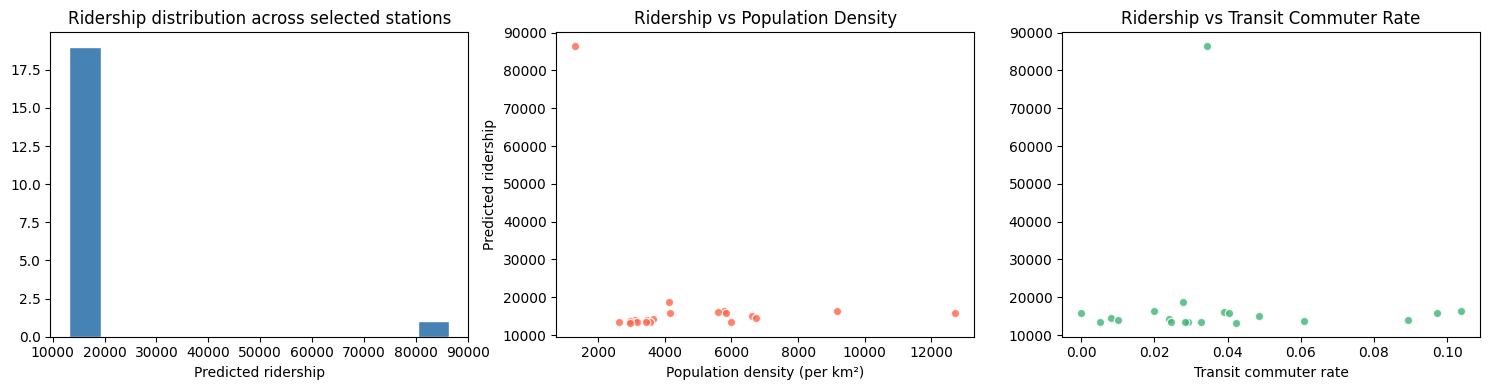

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(selected['predicted_ridership'], bins=12, color='steelblue', edgecolor='white')
axes[0].set_title('Ridership distribution across selected stations')
axes[0].set_xlabel('Predicted ridership')

axes[1].scatter(selected['population_density'], selected['predicted_ridership'],
                alpha=0.8, color='tomato', edgecolors='white')
axes[1].set_title('Ridership vs Population Density')
axes[1].set_xlabel('Population density (per km²)')
axes[1].set_ylabel('Predicted ridership')

axes[2].scatter(selected['transit_commuter_rate'], selected['predicted_ridership'],
                alpha=0.8, color='mediumseagreen', edgecolors='white')
axes[2].set_title('Ridership vs Transit Commuter Rate')
axes[2].set_xlabel('Transit commuter rate')

plt.tight_layout()
# plt.savefig('sj_diagnostics.png', dpi=150)
plt.show()